# Model Comparison

Add tuned KNN and Decision Tree models and run comparison experiments against the baseline models.

## Setup

In [1]:
import sys
sys.path.append("../src")
from read_data import load_data
from preprocess import prepare_data, build_preprocessor
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from evaluation import cv_model
import matplotlib.pyplot as plt

## Load and preprocess the data

Use the same random_state=42 and 5-fold cv on all models

In [2]:
df = load_data()
X, y = prepare_data(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Training rows:", X_train.shape)
print("Test rows:", X_test.shape)

Training rows: (429, 7)
Test rows: (108, 7)


## KNN Regressor

Test different values of k, weights and p to find the best KNN settings. 

In [3]:
knn = make_pipeline(build_preprocessor(), KNeighborsRegressor())
#range of neighbours to test
neighbours= [3, 5, 7, 11, 21]
param_grid = {"kneighborsregressor__n_neighbors": neighbours,
    "kneighborsregressor__weights": ["uniform", "distance"],
    "kneighborsregressor__p": [1, 2]
}

# GridSearchCV tries every combination. best_params_ shows the best settings
# best_score_ is the MAE scored by best_param
knn_search = GridSearchCV(knn, param_grid, cv=cv, scoring="neg_mean_absolute_error")
knn_search.fit(X_train, y_train)
print("Best KNN settings:", knn_search.best_params_)
print(f"Best KNN MAE: {-knn_search.best_score_:.2f}")



Best KNN settings: {'kneighborsregressor__n_neighbors': 11, 'kneighborsregressor__p': 1, 'kneighborsregressor__weights': 'distance'}
Best KNN MAE: 11.18


## KNN validation graph

For each number of neighbours k, show the best crossvalidation MAE found across all weight and distance values

knn
3     13.344429
5     12.358319
7     11.789850
11    11.179346
21    11.485092
Name: MAE, dtype: float64

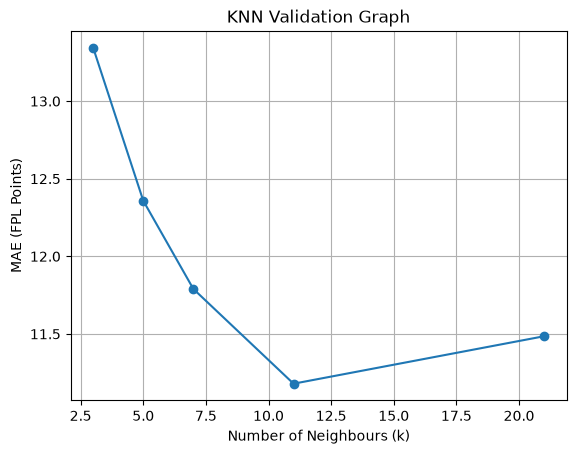

In [4]:
knn_results = pd.DataFrame(knn_search.cv_results_)
knn_results["knn"] = knn_results["param_kneighborsregressor__n_neighbors"]
knn_results["MAE"] = -knn_results["mean_test_score"]
knn_data = knn_results.groupby("knn")["MAE"].min()
display(knn_data)

knn_data.plot(marker="o")
plt.xlabel("Number of Neighbours (k)")
plt.ylabel("MAE (FPL Points)")
plt.title("KNN Validation Graph")
plt.grid(True)
plt.show()

MAE is highest at k=3 and falls up to k=11, then rises at k=21. 
Small k overfits and large k oversmooths.
k=11 is the best balance. 

## Decision Tree Regressor 

Test different values of max depth and minimum leaf size to find the best tree settings

In [5]:
tree = make_pipeline(build_preprocessor(), DecisionTreeRegressor(random_state=42))
#Test these depth levels and leaf sizes
tree_params = {
    "decisiontreeregressor__max_depth": [3, 5, 7, 10],
    "decisiontreeregressor__min_samples_leaf": [2, 5, 10]
}

tree_search = GridSearchCV(
    tree, tree_params, cv=cv, scoring="neg_mean_absolute_error"
)
tree_search.fit(X_train, y_train)
print("Best tree settings:", tree_search.best_params_)
print(f"Best tree CV MAE: {-tree_search.best_score_:.2f}")

Best tree settings: {'decisiontreeregressor__max_depth': 10, 'decisiontreeregressor__min_samples_leaf': 10}
Best tree CV MAE: 11.80


### Decision Tree validation graph

Shows the lowest MAE at each tree depth, using the best leaf size for that depth.

depth
3     13.597785
5     12.203991
7     11.809287
10    11.803431
Name: MAE, dtype: float64

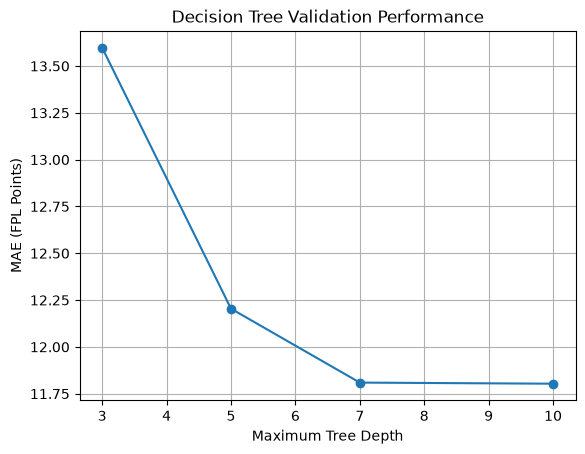

In [6]:
tree_results = pd.DataFrame(tree_search.cv_results_)
tree_results["depth"] = tree_results["param_decisiontreeregressor__max_depth"]
tree_results["MAE"] = -tree_results["mean_test_score"]
tree_data = tree_results.groupby("depth")["MAE"].min()
display(tree_data)


tree_data.plot(marker="o")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("MAE (FPL Points)")
plt.title("Decision Tree Validation Performance")
plt.grid(True)
plt.show()

MAE drops between depths 3 to 7 then levels around MAE 11.8. Increasing depth gave no improvement.

## Compare models against baseline

Compare models on MAE, RMSE, R² and MAE standard deviation, all under the same 5-fold
cross validation on the training data.

In [7]:
# Build the baseline models in the same preprocessing pipeline
dummy = make_pipeline(build_preprocessor(), DummyRegressor(strategy="mean"))
linreg = make_pipeline(build_preprocessor(), LinearRegression())

In [8]:
# Run every model through the same folds
dummy_cv = cv_model(dummy,X_train,y_train)
lr_cv = cv_model(linreg,X_train,y_train)
knn_cv = cv_model(knn_search.best_estimator_, X_train, y_train)
tree_cv = cv_model(tree_search.best_estimator_, X_train, y_train)

results = {
    "Dummy": dummy_cv,
    "Linear Regression": lr_cv,
    "KNN": knn_cv,
    "Decision Tree": tree_cv
}

# Primary metric MAE, secondary RMSE and R2, plus MAE std for fold-to-fold variability
comparison = pd.DataFrame({
    "Model": list(results.keys()),
    "MAE":     [result["MAE"].mean()  for result in results.values()],
    "MAE_std": [result["MAE"].std()   for result in results.values()],
    "RMSE":    [result["RMSE"].mean() for result in results.values()],
    "R2":      [result["R2"].mean()   for result in results.values()],
})
display(comparison.round(2))


,Model,MAE,MAE_std,RMSE,R2
0,Dummy,41.84,2.19,49.80,-0.00
1,Linear Regression,9.85,0.72,12.89,0.93
2,KNN,11.18,0.70,15.31,0.91
3,Decision Tree,11.80,0.84,17.41,0.88


All three learned models beat the dummy baseline by a big margin.  
Of the three learned models, Linear Regression is best with lowest MAE and highest R².
kNN is next best MAE and similar R². 
The decision tree is the weakest learned model, with highest MAE and most variable across folds shown with MAE_std.  
RMSE is higher than MAE for all models which inidcates some large mistakes in all models.

#### Compare training and predicting times

In [9]:
# Training and prediction costs
timing = pd.DataFrame({
    "Model": list(results.keys()),
    "Training time (secs)":   [result["fit_time"].mean() for result in results.values()],
    " Predict time (secs)": [result["score_time"].mean() for result in results.values()],
})
print(timing)

               Model  Training time (secs)   Predict time (secs)
0              Dummy              0.008968              0.005341
1  Linear Regression              0.009952              0.004956
2                KNN              0.010064              0.011435
3      Decision Tree              0.011244              0.005782


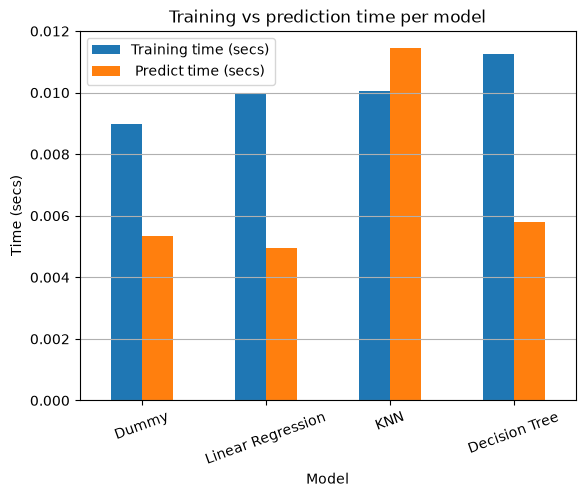

In [10]:
timing_plot = timing.set_index("Model")
timing_plot.plot(kind="bar")
plt.ylabel("Time (secs)")
plt.title("Training vs prediction time per model")
plt.xticks(rotation=20)
plt.grid(True, axis="y")
plt.show()

## Error analysis

Error analysis looks at where the models go wrong. 

In [11]:
# Predict using the training data and cross-validation
knn_best = knn_search.best_estimator_
tree_best = tree_search.best_estimator_

knn_pred = cross_val_predict(knn_best, X_train, y_train, cv=cv)
tree_pred = cross_val_predict(tree_best, X_train, y_train, cv=cv)
lr_pred = cross_val_predict(linreg, X_train, y_train, cv=cv)


#Make a table to compare actual fpl points to what was predicted by the models
errors = pd.DataFrame({
    "actual": y_train,
    "knn_pred": knn_pred,
    "tree_pred": tree_pred,
    "lr_pred": lr_pred
})

display(errors.head(5))


,actual,knn_pred,tree_pred,lr_pred
794,49,38.207048,34.352941,46.519694
308,136,140.347254,145.058824,115.852857
551,3,6.331637,3.250000,-3.163581
287,13,17.567071,17.000000,16.168384
476,108,115.227939,132.235294,117.006919


### Worst predictions for each model
List the 5 worst for each learned model

In [12]:
#Calculate difference of real fpl points and the predictions
errors["knn_error"] = errors["knn_pred"] - errors["actual"]
errors["tree_error"] = errors["tree_pred"] - errors["actual"]
errors["lr_error"] = errors["lr_pred"] - errors["actual"]

In [13]:
# List the 5 worst predcitions for each model
errors["knn_abs"] = errors["knn_error"].abs()
errors["tree_abs"] = errors["tree_error"].abs()
errors["lr_abs"] = errors["lr_error"].abs()

print("KNN — worst 5 predictions")
display(errors.sort_values("knn_abs", ascending=False)
              [["actual", "knn_pred", "knn_error"]].head().round(2))

print("Tree — worst 5 predictions")
display(errors.sort_values("tree_abs", ascending=False)
              [["actual", "tree_pred", "tree_error"]].head().round(2))

print("Linear Regression — worst 5 predictions")
display(errors.sort_values("lr_abs", ascending=False)
              [["actual", "lr_pred", "lr_error"]].head().round(2))

KNN — worst 5 predictions


,actual,knn_pred,knn_error
552,235,167.85,-67.15
525,239,177.87,-61.13
505,154,101.04,-52.96
779,187,140.34,-46.66
515,135,89.00,-46.00


Tree — worst 5 predictions


,actual,tree_pred,tree_error
525,239,140.13,-98.87
552,235,160.84,-74.16
720,116,186.55,70.55
779,187,132.24,-54.76
92,85,137.40,52.40


Linear Regression — worst 5 predictions


,actual,lr_pred,lr_error
682,80,125.13,45.13
426,68,110.00,42.00
632,188,152.30,-35.70
175,136,100.70,-35.30
401,91,124.57,33.57


Players 525 and 552 have very high FPL points and were underpredicted by both KNN and Decision Tree. KNN mainly underpredicts high-scoring players. Decision Tree makes large underprediction and overprediction errors. Linear Regression also overpredicts and underpredicts some players, but its five largest errors are smaller than those of KNN and Decision Tree.

### Error analysis by point bands
Group players into low, medium and high fpl points and show the average error for each band.

In [14]:
print("Training set points range:")
print("min:", y_train.min())
print("max:", y_train.max())
print("count:", len(y_train))
print(y_train.describe())

Training set points range:
min: 0
max: 239
count: 429
count    429.000000
mean      64.431235
std       49.984933
min        0.000000
25%       17.000000
50%       56.000000
75%      103.000000
max      239.000000
Name: total_points, dtype: float64


In [15]:
# Slice the errors into fpl point bands from low, medium and high scorers
max_value=errors["actual"].max()
bands = pd.cut(errors["actual"],
               bins=[0, 30, 80, max_value],
               labels=["Low (0-30)", "Medium (30-80)", "High (80+)"])
bands = bands.rename("Band")

print("Average error per band. Negative shows under prediction and positive shows over prediction")
display(errors.groupby(bands)[["knn_error", "tree_error","lr_error"]].mean().round(2))


Average error per band. Negative shows under prediction and positive shows over prediction


,knn_error,tree_error,lr_error
Band,,,
Low (0-30),4.00,1.76,2.43
Medium (30-80),-0.24,2.77,1.65
High (80+),-11.87,-4.77,-3.67


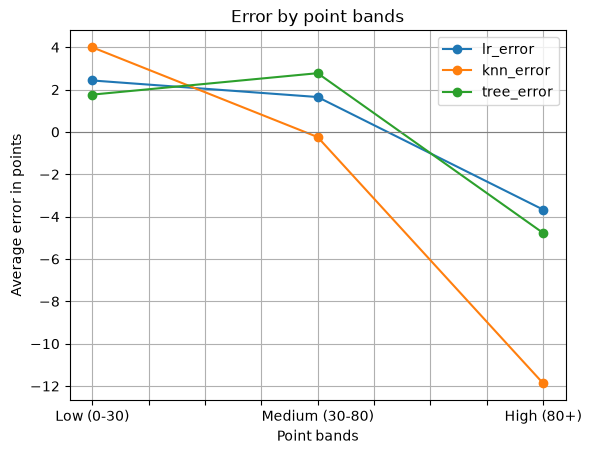

In [16]:
average_errors = errors.groupby(bands)[["lr_error", "knn_error", "tree_error"]].mean()

average_errors.plot(marker="o")
plt.axhline(0, color="grey", linewidth=0.8)  
plt.ylabel("Average error in points")
plt.xlabel("Point bands")
plt.title("Error by point bands")
plt.grid(True)
plt.show()

This graph shows how the models differ. KNN underpredicts high scorers by about 12 points on average, compared with Decision Tree 4.7 and Linear Regression 3.6. All three models slightly overpredict low scorers. KNN has almost no average error for medium scorers. Linear Regression has the smallest average error for high scorers.

## Decision tree plot 
Plotting the top levels of the tuned tree to see which features it splits on.

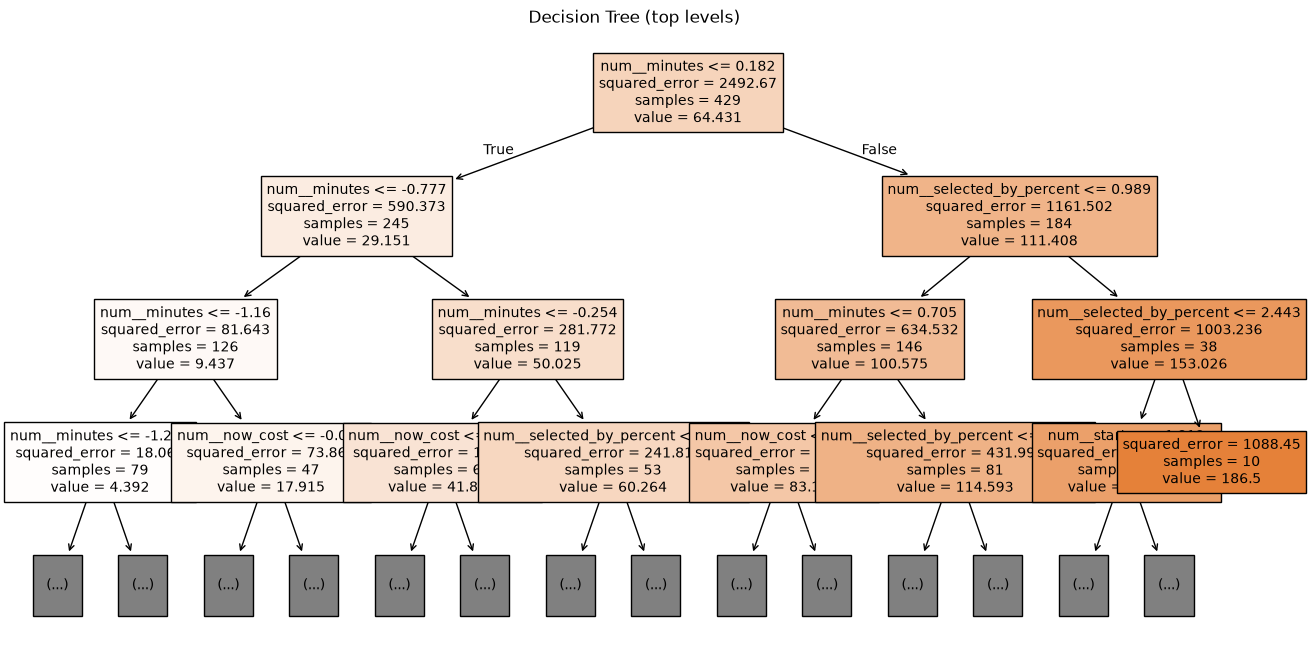

In [17]:
from sklearn.tree import plot_tree

# Get the fitted tree out of the pipeline, and the feature names after preprocessing
fitted_tree = tree_best.named_steps["decisiontreeregressor"]
feature_names = tree_best.named_steps["columntransformer"].get_feature_names_out()

# Plot only the top of the tree
plt.figure(figsize=(16, 8))
plot_tree(fitted_tree,
          feature_names=feature_names,
          filled=True,
          max_depth=3,
          fontsize=10)
plt.title("Decision Tree (top levels)")
plt.show()

The tree splits first on minutes in the tree, then on now_cost and selected_by_percent.

## Conclusion

I compared four models using five-fold cross validation: Dummy Regressor, Linear Regression, KNN and Decision Tree.

Linear Regression gave the best results, with the lowest MAE and the highest R². KNN and Decision Tree both performed much better with much lower MAE than the Dummy baseline but neither was as good as Linear Regression.

Looking at the prediction errors, all three learned models tend to underpredict players with high FPL points (80+). This was worst with KNN, which underpredicted these players by almost 12 points on average. This shows that the models find it harder to predict high point players.

### Best Model Settings
- **Linear Regression:** Default settings, no tuning. Best overall performance 
- **KNN:** 11 neighbours, Manhattan distance (p=1), distance weighting. Second best model.
- **Decision Tree:** Maximum depth 10, minimum samples per leaf 10. Third best model.
- **Dummy Regressor:** Mean strategy. This was the baseline model.

My next step is to try Random Forest, which is an ensemble of trees. I want to see if this can improve the prediction accuracy compared to a single Decision Tree. I will then compare Random Forest with the other models using the same cross-validation method.